# Trajectory Optimization in a Non-Uniform River Flow

### A step-by-step notebook for the swimmer's path-planning problem

This notebook explains **Case 3** from the accompanying project report: a swimmer moves through a spatially varying river current while keeping a constant swimming speed relative to the water. The swimmer can change their heading at each discrete time step. A gradient-descent algorithm searches for a sequence of headings that brings the swimmer as close as possible to a specified target on the opposite bank.

**Scope:** this notebook covers only the non-uniform-flow case. It does not implement either of the two uniform-flow cases.

**Related files:**
- Research report: `../docs/Simple_Path_Planning_Report.pdf` (especially Sections 2.3, 2.4, and 3.3).
- Runnable command-line version: `../demo.py`.
- Uploaded original script, kept unchanged: `../original/Path_Planning_Nonuniform.py`.

The notebook is self-contained: its cells define the model and optimizer directly, so it can be run from top to bottom without importing `demo.py`.

## Learning objectives

By the end, you should be able to explain:

1. How the river's velocity field is defined using a source–sink pair and a uniform background current.
2. Why the swimmer's ground velocity is the vector sum of the swimming velocity and the local river velocity.
3. How forward-Euler time stepping turns the motion model into a simulation.
4. How the final-position error defines the optimization objective.
5. How central finite differences estimate the gradient and how gradient descent updates the heading sequence.
6. How to interpret the resulting path and convergence plots.

### Dependencies

The notebook uses only **NumPy** and **Matplotlib**, which are also the main dependencies of the command-line demo. If necessary, install them with:

```bash
python -m pip install numpy matplotlib
```

## 1. Physical model and coordinate system

The river is represented in two dimensions:

- The **x-axis** runs across the river, from the starting bank to the opposite bank.
- The **y-axis** is the vertical coordinate in the diagram. The uniform background current points in the negative-y direction in the report's convention.
- The swimmer starts at \(\mathbf r_0=(-D/2,0)\) and aims for \(\mathbf r_t=(D/2,y_t)\), where \(D\) is the river width.
- The swimmer's speed relative to the local water is constant, \(u_m\), but the heading \(\theta_k\) is allowed to vary at every time step.
- The ground velocity is affected by both the swimmer and the river current.

The total simulation duration \(T\) is chosen in advance and split into \(N\) time steps, each of duration \(\Delta t=T/N\). In this formulation the optimizer minimizes endpoint error at the end of this fixed horizon; it does **not** separately optimize the crossing time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

np.set_printoptions(precision=4, suppress=True)

print("NumPy version:", np.__version__)
print("Ready to model and optimize the non-uniform-flow case.")

NumPy version: 2.3.5
Ready to model and optimize the non-uniform-flow case.


## 2. Parameters

The defaults below are chosen to match the supplied Python script for its initial setup. In particular, the notebook uses `target_y = 0.0` to match the uploaded script. **The report's Table 3 lists a target height of 5 m for its example cases**, so that difference is worth keeping in mind when comparing numerical results.

The parameters `x1, y1` and `x2, y2` are the centres of the source and sink terms, respectively. `Q` controls their strength, while `V` is the uniform background-current speed.

In [2]:
@dataclass(frozen=True)
class RiverParameters:
    """Parameters for the non-uniform river-flow field."""
    width: float = 10.0
    x1: float = -1.0
    y1: float = 1.0
    x2: float = 1.0
    y2: float = -1.0
    Q: float = 2.0
    V: float = 0.5

params = RiverParameters()

target_y = 0.0              # m; matches the uploaded script
swimmer_speed = 1.0         # m/s, relative to the water
num_steps = 100             # number of heading controls
total_time = 12.7          # seconds

In [3]:
dt = total_time / num_steps
initial_angle = 0.87         # radians; same initial guess at every step
initial_angles = np.full(num_steps, initial_angle, dtype=float)

learning_rate = 0.01
finite_difference_step = 1e-3
endpoint_tolerance = 0.1    # metres
max_iterations = 400

start = (-params.width / 2.0, 0.0)
target = (params.width / 2.0, target_y)

print(f"River width:              {params.width:.2f} m")
print(f"Start:                    {start}")
print(f"Target:                   {target}")
print(f"Swimmer speed:            {swimmer_speed:.2f} m/s")
print(f"Total simulated time:     {total_time:.2f} s")
print(f"Number of time steps:     {num_steps}")
print(f"Time step, Δt:            {dt:.4f} s")
print(f"Initial heading:          {np.degrees(initial_angle):.2f} degrees")
print(f"Gradient-descent rate:    {learning_rate}")

River width:              10.00 m
Start:                    (-5.0, 0.0)
Target:                   (5.0, 0.0)
Swimmer speed:            1.00 m/s
Total simulated time:     12.70 s
Number of time steps:     100
Time step, Δt:            0.1270 s
Initial heading:          49.85 degrees
Gradient-descent rate:    0.01


## 3. The non-uniform river-flow field

The report represents the river as a source–sink pair superimposed on a uniform background current. Define the squared distances to the two centres as

\[
\rho_1^2=(x-x_1)^2+(y-y_1)^2,\qquad
\rho_2^2=(x-x_2)^2+(y-y_2)^2.
\]

The two components of the flow velocity are

\[
f_x(x,y)=\frac{Q}{2\pi}\left(\frac{x-x_1}{\rho_1^2}-\frac{x-x_2}{\rho_2^2}\right),
\]

\[
f_y(x,y)=-V+\frac{Q}{2\pi}\left(\frac{y-y_1}{\rho_1^2}-\frac{y-y_2}{\rho_2^2}\right).
\]

The \(-V\) term is the uniform current toward decreasing \(y\). The remaining terms make the flow change with position. Because the idealized point-flow expression is singular at the source and sink centres, the implementation applies a very small lower bound to each denominator as a numerical safeguard.

**Important reading note:** the uploaded script first sets `R1` and `R2` to squared distances and then squares them again in the denominators. Section 2.3 of the report instead defines `R1` and `R2` as distances and divides by their squares. The implementation below follows the equation written in the report; the original script remains preserved separately in the repository.

In [4]:
def river_flow(x, y, params=params):
    """Return the river velocity components (f_x, f_y) at position (x, y).

    x and y may be scalars or NumPy arrays. The denominator floor prevents
    division by zero at the idealized source/sink centres.
    """
    rho1_sq = np.maximum((x - params.x1)**2 + (y - params.y1)**2, 1e-8)
    rho2_sq = np.maximum((x - params.x2)**2 + (y - params.y2)**2, 1e-8)
    factor = params.Q / (2.0 * np.pi)

    flow_x = factor * (
        (x - params.x1) / rho1_sq
        - (x - params.x2) / rho2_sq
    )
    flow_y = -params.V + factor * (
        (y - params.y1) / rho1_sq
        - (y - params.y2) / rho2_sq
    )
    return flow_x, flow_y

# Example: evaluate the river current at the starting point.
flow_at_start = river_flow(start[0], start[1], params)
print("River-flow velocity at start (m/s):", flow_at_start)

River-flow velocity at start (m/s): (np.float64(-0.0232786244267955), np.float64(-0.5273270808488469))


### Visualizing the flow before adding the swimmer

A stream plot shows the local directions of the river velocity. The flow is not uniform: the source–sink pair bends the streamlines. The points marked with crosses are the centres of the two terms in the model, not physical obstacles represented explicitly by this code.

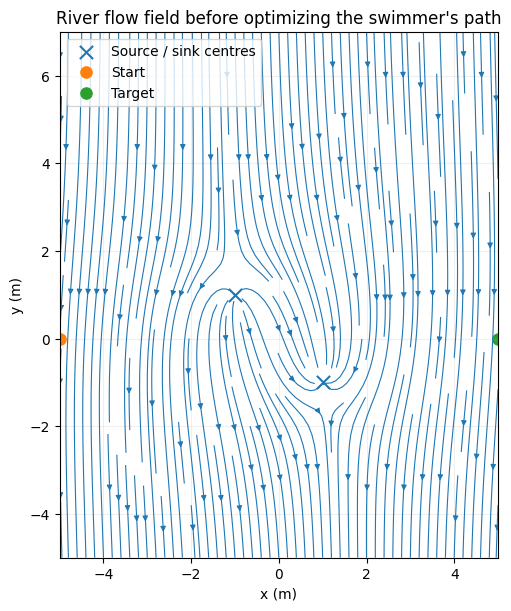

In [5]:
grid_x, grid_y = np.meshgrid(
    np.linspace(-params.width / 2.0, params.width / 2.0, 120),
    np.linspace(-5.0, 7.0, 120),
)
flow_grid_x, flow_grid_y = river_flow(grid_x, grid_y, params)

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.streamplot(grid_x, grid_y, flow_grid_x, flow_grid_y, density=1.7,
              linewidth=0.8, arrowsize=0.8)
ax.scatter([params.x1, params.x2], [params.y1, params.y2],
           marker="x", s=90, label="Source / sink centres")
ax.scatter([start[0]], [start[1]], s=65, label="Start")
ax.scatter([target[0]], [target[1]], s=65, label="Target")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("River flow field before optimizing the swimmer's path")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)
ax.legend()
plt.show()

## 4. From river flow to the swimmer's ground velocity

At time step \(k\), the swimmer selects heading \(\theta_k\). Their velocity **relative to the water** is

\[
\mathbf u_{m,k}=\begin{bmatrix}u_m\cos\theta_k\\u_m\sin\theta_k\end{bmatrix}.
\]

The current at the swimmer's current position \((x_k,y_k)\) is \(\mathbf f(x_k,y_k)=[f_x,f_y]^T\). The ground velocity is the vector sum:

\[
\mathbf u_{\mathrm{total},k}=\begin{bmatrix}
u_m\cos\theta_k+f_x(x_k,y_k)\\u_m\sin\theta_k+f_y(x_k,y_k)\end{bmatrix}.
\]

This distinction matters: the heading angle describes where the swimmer points relative to the water, while the ground-velocity direction describes where the swimmer actually travels. They are generally different.

## 5. Discretizing the swimmer's trajectory

The continuous motion law is \(d\mathbf r/dt=\mathbf u_{\mathrm{total}}\). With a forward-Euler (explicit finite-difference) step, the position is advanced using the velocity evaluated at the current point:

\[
x_{k+1}=x_k+\Delta t\,[u_m\cos\theta_k+f_x(x_k,y_k)],
\]
\[
y_{k+1}=y_k+\Delta t\,[u_m\sin\theta_k+f_y(x_k,y_k)].
\]

Repeating these updates for all \(N\) headings gives a predicted path and final endpoint. This is what the following function does.

In [6]:
def simulate_path(angles, dt, swimmer_speed, target_y, params=params):
    """Simulate a complete path for a sequence of heading angles.

    Returns
    -------
    cost : squared distance from final position to target
    x_final, y_final : endpoint coordinates
    x_history, y_history : arrays containing the start plus every step
    """
    x = -params.width / 2.0
    y = 0.0
    x_history = [x]
    y_history = [y]

    for theta in angles:
        flow_x, flow_y = river_flow(x, y, params)
        total_vx = swimmer_speed * np.cos(theta) + flow_x
        total_vy = swimmer_speed * np.sin(theta) + flow_y

        x += dt * total_vx
        y += dt * total_vy
        x_history.append(float(x))
        y_history.append(float(y))

    cost = (x - params.width / 2.0)**2 + (y - target_y)**2
    return (float(cost), float(x), float(y),
            np.asarray(x_history), np.asarray(y_history))

### Simulate the initial guess

Before optimization, every step uses the same heading \(\theta_k=0.87\) rad (about 49.8°). This is only the **initial guess**. It is not assumed to be optimal.

Initial endpoint: (2.767, 3.696) m
Target:           (5.000, 0.000) m
Initial distance error: 4.318 m


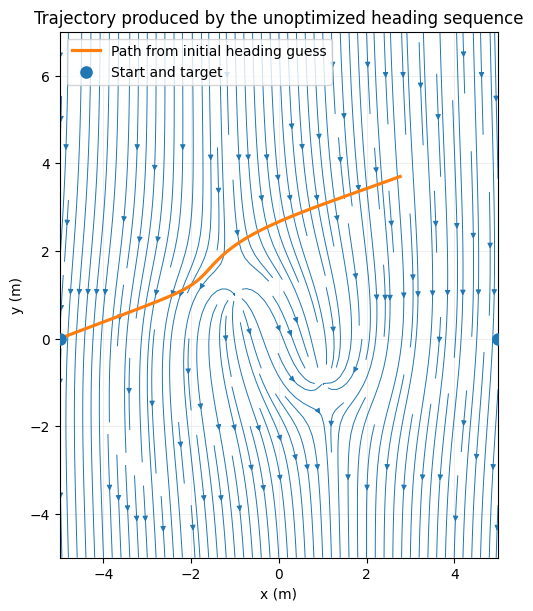

In [7]:
initial_cost, x_initial, y_initial, x_initial_path, y_initial_path = simulate_path(
    initial_angles, dt, swimmer_speed, target_y, params
)
initial_error = np.sqrt(initial_cost)

print(f"Initial endpoint: ({x_initial:.3f}, {y_initial:.3f}) m")
print(f"Target:           ({target[0]:.3f}, {target[1]:.3f}) m")
print(f"Initial distance error: {initial_error:.3f} m")

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.streamplot(grid_x, grid_y, flow_grid_x, flow_grid_y, density=1.7,
              linewidth=0.7, arrowsize=0.8)
ax.plot(x_initial_path, y_initial_path, linewidth=2.3,
        label="Path from initial heading guess")
ax.scatter([start[0], target[0]], [start[1], target[1]], s=65,
           label="Start and target", zorder=5)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Trajectory produced by the unoptimized heading sequence")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)
ax.legend()
plt.show()

## 6. The objective function

The target is \(\mathbf r_t=(D/2,y_t)\) and the endpoint predicted from the heading sequence is \(\mathbf r_N(\boldsymbol\theta)=(x_N,y_N)\). The optimizer minimizes the **squared endpoint distance**:

\[
J(\boldsymbol\theta)=(x_N-x_t)^2+(y_N-y_t)^2.
\]

The square root \(\sqrt{J}\) is the easier-to-interpret distance error, measured in metres. Squaring the distance makes the objective smooth for differentiation and gives the same minimizer as minimizing the distance itself.

There are \(N\) decision variables:

\[
\boldsymbol\theta=[\theta_0,\theta_1,\ldots,\theta_{N-1}].
\]

Changing an early angle can affect all subsequent positions, because every later step starts from the position reached in the previous step.

In [8]:
def cost_for_angles(angles):
    """Convenience wrapper: return just the objective value J(theta)."""
    return simulate_path(angles, dt, swimmer_speed, target_y, params)[0]

print(f"J(initial angles) = {cost_for_angles(initial_angles):.6f} m^2")
print(f"Distance error    = {np.sqrt(cost_for_angles(initial_angles)):.6f} m")

J(initial angles) = 18.645512 m^2
Distance error    = 4.318045 m


## 7. Estimate the gradient with central finite differences

Gradient descent needs each partial derivative \(\partial J/\partial\theta_i\). Instead of deriving all these derivatives analytically through the full trajectory recursion, the code approximates them numerically:

\[
\frac{\partial J}{\partial\theta_i}\approx
\frac{J(\boldsymbol\theta+\varepsilon\mathbf e_i)-
      J(\boldsymbol\theta-\varepsilon\mathbf e_i)}{2\varepsilon}.
\]

Here, \(\mathbf e_i\) is a vector whose only nonzero component is 1 at index \(i\), and \(\varepsilon\) is a small angle perturbation in radians. Each angle is perturbed once upward and once downward, so \(2N\) perturbed sequences are evaluated to estimate the full gradient.

The original script does these simulations in nested loops. The implementation below evaluates those perturbations as a batch using NumPy arrays. This changes how the calculations are organized for speed, not the central-difference formula.

In [9]:
def batch_costs(angle_sequences, dt, swimmer_speed, target_y, params=params):
    """Evaluate J for many angle sequences in parallel.

    angle_sequences has shape (batch_size, number_of_steps). Each row is
    one candidate heading sequence.
    """
    batch_size, n_steps = angle_sequences.shape
    x = np.full(batch_size, -params.width / 2.0, dtype=float)
    y = np.zeros(batch_size, dtype=float)

    for k in range(n_steps):
        flow_x, flow_y = river_flow(x, y, params)
        theta_k = angle_sequences[:, k]
        x += dt * (swimmer_speed * np.cos(theta_k) + flow_x)
        y += dt * (swimmer_speed * np.sin(theta_k) + flow_y)

    return (x - params.width / 2.0)**2 + (y - target_y)**2


def central_difference_gradient(angles, dt, swimmer_speed, target_y,
                                params=params, fd_step=1e-3):
    """Approximate all partial derivatives of J with central differences."""
    n_steps = len(angles)
    perturbed = np.repeat(angles[np.newaxis, :], 2 * n_steps, axis=0)
    indices = np.arange(n_steps)
    perturbed[2 * indices, indices] += fd_step
    perturbed[2 * indices + 1, indices] -= fd_step

    costs = batch_costs(perturbed, dt, swimmer_speed, target_y, params)
    gradient = (costs[0::2] - costs[1::2]) / (2.0 * fd_step)
    return gradient

initial_gradient = central_difference_gradient(
    initial_angles, dt, swimmer_speed, target_y, params,
    fd_step=finite_difference_step
)
print("Gradient shape:", initial_gradient.shape)
print("First five gradient components:", initial_gradient[:5])
print("Gradient norm:", f"{np.linalg.norm(initial_gradient):.4f}")

Gradient shape: (100,)
First five gradient components: [0.7613 0.7601 0.7588 0.7575 0.7562]
Gradient norm: 9.7991


## 8. Gradient-descent update

Once the gradient is estimated, the heading sequence is updated by

\[
\boldsymbol\theta^{(j+1)}=
\boldsymbol\theta^{(j)}-\eta\nabla J(\boldsymbol\theta^{(j)}),
\]

where \(j\) is the optimization iteration and \(\eta>0\) is the learning rate. The minus sign points the update downhill, toward smaller objective values.

Each iteration of the implementation:

1. estimates the gradient for the current heading sequence;
2. updates all angles;
3. simulates the updated sequence to calculate the new endpoint error;
4. stores the cost for the convergence plot; and
5. stops if the endpoint is within the requested tolerance or if the iteration limit is reached.

The method is sensitive to the learning rate and initial guess. It is not a guarantee of finding a global optimum, and this implementation does not impose bounds on the angle values.

In [10]:
def optimize_angles(initial_angles, dt, swimmer_speed, target_y, params,
                    learning_rate, fd_step, tolerance, max_iterations):
    """Optimize the heading sequence using gradient descent.

    Returns the optimized angles, objective history, and a tolerance flag.
    """
    angles = np.asarray(initial_angles, dtype=float).copy()
    cost_history = []
    converged = False

    for iteration in range(max_iterations):
        gradient = central_difference_gradient(
            angles, dt, swimmer_speed, target_y, params, fd_step
        )
        angles -= learning_rate * gradient

        cost, x_end, y_end, _, _ = simulate_path(
            angles, dt, swimmer_speed, target_y, params
        )
        distance_error = float(np.sqrt(cost))
        cost_history.append(cost)

        if distance_error <= tolerance:
            converged = True
            break

    return angles, cost_history, converged

optimized_angles, cost_history, converged = optimize_angles(
    initial_angles=initial_angles,
    dt=dt,
    swimmer_speed=swimmer_speed,
    target_y=target_y,
    params=params,
    learning_rate=learning_rate,
    fd_step=finite_difference_step,
    tolerance=endpoint_tolerance,
    max_iterations=max_iterations,
)

final_cost, final_x, final_y, path_x, path_y = simulate_path(
    optimized_angles, dt, swimmer_speed, target_y, params
)
final_error = np.sqrt(final_cost)

print(f"Iterations performed: {len(cost_history)} / {max_iterations}")
print(f"Final position:       ({final_x:.4f}, {final_y:.4f}) m")
print(f"Target position:      ({target[0]:.4f}, {target[1]:.4f}) m")
print(f"Final distance error: {final_error:.4f} m")
print("Tolerance reached:", converged)
print(f"Mean heading:         {np.degrees(np.mean(optimized_angles)):.2f} degrees")

Iterations performed: 288 / 400
Final position:       (4.9011, 0.0141) m
Target position:      (5.0000, 0.0000) m
Final distance error: 0.0999 m
Tolerance reached: True
Mean heading:         31.67 degrees


## 9. Interpret the optimization results

### 9.1 Convergence history

The plot uses \(\sqrt{J}\), rather than \(J\), so the vertical axis represents the swimmer's distance from the target in metres. A downward trend indicates that the optimization is improving the endpoint. Small oscillations or plateaus can occur with an overly large or poorly chosen learning rate.

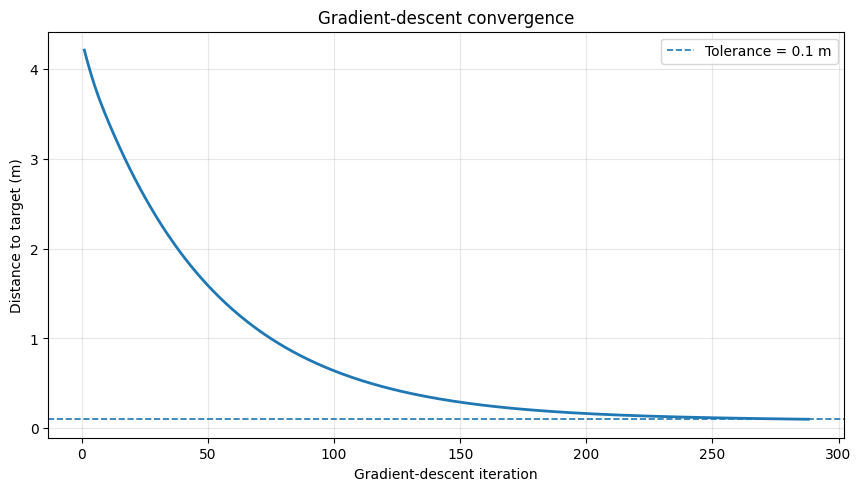

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
ax.plot(np.arange(1, len(cost_history) + 1), np.sqrt(cost_history), linewidth=2)
ax.axhline(endpoint_tolerance, linestyle="--", linewidth=1.2,
           label=f"Tolerance = {endpoint_tolerance:g} m")
ax.set_xlabel("Gradient-descent iteration")
ax.set_ylabel("Distance to target (m)")
ax.set_title("Gradient-descent convergence")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### 9.2 The optimized path

The next plot places the trajectory on top of the river streamlines. The optimizer selects a different heading at different time steps to compensate for the local current and reduce the final position error. The trajectory is computed by integrating the **combined** velocity, not by following a streamline of the river alone.

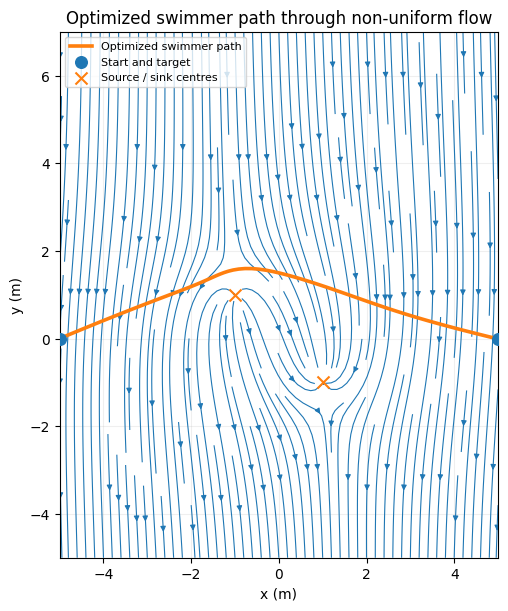

In [12]:
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.streamplot(grid_x, grid_y, flow_grid_x, flow_grid_y, density=1.7,
              linewidth=0.8, arrowsize=0.8)
ax.plot(path_x, path_y, linewidth=2.6, label="Optimized swimmer path")
ax.scatter([start[0], target[0]], [start[1], target[1]], s=70,
           zorder=5, label="Start and target")
ax.scatter([params.x1, params.x2], [params.y1, params.y2],
           marker="x", s=75, zorder=6, label="Source / sink centres")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Optimized swimmer path through non-uniform flow")
ax.set_xlim(-params.width / 2.0, params.width / 2.0)
ax.set_ylim(-5.0, 7.0)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)
ax.legend(loc="best", fontsize=8)
plt.show()

### 9.3 Heading direction versus actual motion direction

The short arrows below compare:

- **Swimmer heading:** \([\cos\theta_k,\sin\theta_k]\), the direction in which the swimmer points relative to the water.
- **Ground-velocity direction:** the normalized sum of the swimmer's velocity and the local flow velocity.

Their difference shows how the river current changes the actual path even when the swimmer's own heading is controlled.

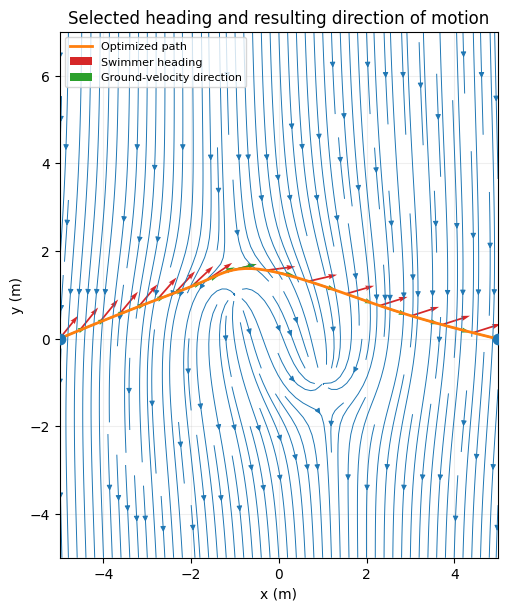

In [13]:
sample_indices = np.arange(0, len(optimized_angles), max(1, len(optimized_angles) // 15))
x_sample = path_x[sample_indices]
y_sample = path_y[sample_indices]
theta_sample = optimized_angles[sample_indices]

local_flow_x, local_flow_y = river_flow(x_sample, y_sample, params)
total_x = swimmer_speed * np.cos(theta_sample) + local_flow_x
total_y = swimmer_speed * np.sin(theta_sample) + local_flow_y
norm = np.maximum(np.hypot(total_x, total_y), 1e-9)
total_x_unit, total_y_unit = total_x / norm, total_y / norm

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.streamplot(grid_x, grid_y, flow_grid_x, flow_grid_y, density=1.7,
              linewidth=0.7, arrowsize=0.8)
ax.plot(path_x, path_y, linewidth=2.0, label="Optimized path")
ax.quiver(x_sample, y_sample, np.cos(theta_sample), np.sin(theta_sample),
          angles="xy", scale_units="xy", scale=1.5, width=0.004,
          color="tab:red", label="Swimmer heading")
ax.quiver(x_sample, y_sample, total_x_unit, total_y_unit,
          angles="xy", scale_units="xy", scale=1.5, width=0.004,
          color="tab:green", label="Ground-velocity direction")
ax.scatter([start[0], target[0]], [start[1], target[1]], s=55, zorder=5)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Selected heading and resulting direction of motion")
ax.set_xlim(-params.width / 2.0, params.width / 2.0)
ax.set_ylim(-5.0, 7.0)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)
ax.legend(loc="best", fontsize=8)
plt.show()

### 9.4 How the selected heading changes with time

The decision variables form a sequence rather than one constant angle. Viewing the sequence helps reveal how the optimizer adapts its heading over the fixed simulation horizon.

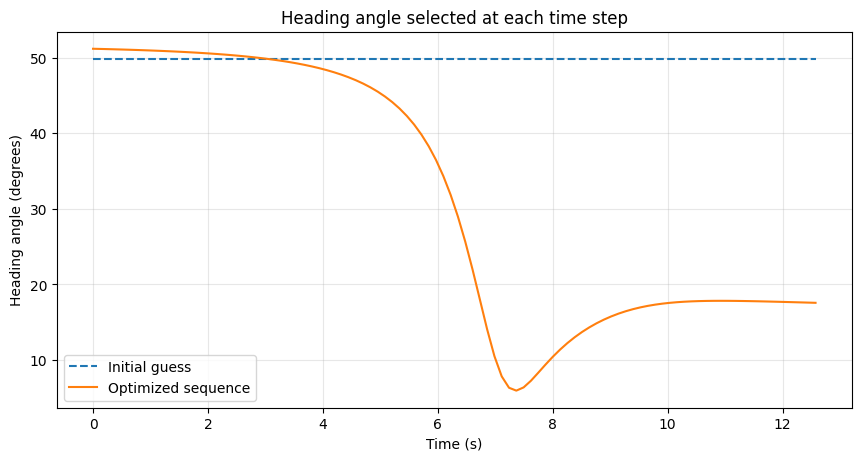

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
time_at_step = np.arange(num_steps) * dt
ax.plot(time_at_step, np.degrees(initial_angles), linestyle="--",
        label="Initial guess")
ax.plot(time_at_step, np.degrees(optimized_angles), label="Optimized sequence")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Heading angle (degrees)")
ax.set_title("Heading angle selected at each time step")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## 10. Try changing parameters

You can experiment with the model without changing the functions above. For example, change `target_y` from `0.0` to `5.0` to test the target height given in Table 3 of the report. Then rerun the cells starting at **“Parameters”** and continue downward.

Other useful experiments:

- Reduce `learning_rate` and compare convergence stability.
- Change `initial_angle` to test sensitivity to the initial guess.
- Change `Q` to make the source–sink disturbance stronger or weaker.
- Change `V` to change the uniform background-current component.
- Change `num_steps` while keeping `total_time` fixed to investigate time discretization.

These quantities interact with each other. A particular configuration may fail to reach the chosen tolerance within the iteration limit. That is a result worth reporting; do not assume that gradient descent always converges to the global optimum.

## 11. Numerical assumptions and limitations

1. **Fixed horizon:** `total_time` is prescribed before optimization. The algorithm minimizes endpoint error at that time, not the total crossing time.
2. **Fixed relative swimming speed:** the swimmer's speed relative to water remains constant; only heading changes.
3. **Stationary flow:** the river velocity field depends on position but not explicitly on time.
4. **Point source/sink model:** the idealized expression is singular at the source and sink centres. A denominator floor prevents a division-by-zero event, but it does not make the physical model realistic near those centres.
5. **Forward-Euler integration:** a finite time step introduces discretization error. Increasing `num_steps` changes both the discretization and the number of optimization variables.
6. **Numerical gradient:** central finite differences require many trajectory evaluations and depend on the perturbation size `finite_difference_step`.
7. **Gradient-descent sensitivity:** learning rate and initialization affect convergence. This simple implementation does not enforce angle bounds, obstacle avoidance, smoothness of the heading sequence, or constraints that keep the swimmer within a physical domain.
8. **Endpoint-only objective:** the cost penalizes the final position only. Intermediate points are not directly penalized for leaving a preferred corridor.

These limitations are important when interpreting this as a tutorial model rather than a complete safety- or navigation-critical swimmer simulator.

## 12. Summary of the algorithm

The computational pipeline for Case 3 is:

1. Define the river-flow field \(\mathbf f(x,y)\).
2. Guess a sequence of heading angles \(\boldsymbol\theta\).
3. Simulate the path with forward-Euler updates.
4. Calculate the squared endpoint error \(J(\boldsymbol\theta)\).
5. Estimate \(\nabla J\) using central finite differences.
6. Update the angle sequence in the negative-gradient direction.
7. Repeat until the target-error tolerance is reached or the iteration limit is hit.
8. Plot the final path and convergence history to interpret the result.

The method links a physical velocity model to a discrete simulation and then to a numerical optimization problem. It produces an approximate heading sequence for the particular model and parameter set; it does not establish that the trajectory is globally optimal for all possible controls.

## Source and reproducibility notes

The methodology and terminology in this notebook follow the supplied report, especially:

- **Section 2.3:** distributed river flow with constant swimmer speed (flow model and trajectory discretization).
- **Section 2.4:** gradient-descent optimization (objective and iterative update).
- **Section 3.3:** distributed-flow simulation examples and parameter discussion.

The notebook's default settings follow the uploaded script for `target_y = 0 m`, `D = 10 m`, `V = 0.5 m/s`, `Q = 2`, `u_m = 1 m/s`, `T = 12.7 s`, and `N = 100`. The report's Table 3 lists `target_y = 5 m` for the examples. The notebook also follows the report's stated source–sink denominator rather than the apparent extra squaring in the uploaded script. These differences are documented intentionally so results can be interpreted and reproduced with the right assumptions.